# iNaturalist

This notebook 
Downloads images
Randomly picks **N images per super category** (default 200 × 11 = 2,200) with a fixed seed.


## 1. Configuration
Just set up some global variables feel free to set these. Think of these as setings 

In [34]:
N_PER_CLASS=200
SEED=42
LABEL_COLUMN="supercategory"  # supercategory = 11 classes; kingdom = 3 classes
SAVE_TO_DRIVE=True
LOCAL_DIR="sample_images"
BASE_URL="https://ml-inat-competition-datasets.s3.amazonaws.com/2021"
ANNOTATION_SOURCE=f"{BASE_URL}/val.json.tar.gz"
IMAGES_SOURCE=f"{BASE_URL}/val.tar.gz"
REDOWNLOAD_IMAGES = True

## 2. Setup

In [35]:
from pathlib import Path
LOCAL_DIR = Path(LOCAL_DIR)
LOCAL_DIR.mkdir(parents=True,exist_ok=True)

## Helper function to open files. 

In [36]:
import os
import requests
# for reading files
def open_stream(source):
    if os.path.exists(source):
        return open(source, "rb")
    r = requests.get(source, stream=True)
    r.raise_for_status()
    r.raw.decode_content = True
    return r.raw

## Get images, labels and categories and join them. 

In [37]:
import json
import tarfile
import pandas as pd

# https://docs.python.org/3/library/tarfile.html
with open_stream(ANNOTATION_SOURCE) as stream:
    with tarfile.open(fileobj=stream, mode="r|gz") as tar:
        member = tar.next()
        json_file = json.load(tar.extractfile(member))

images = pd.DataFrame(json_file["images"]).rename(columns={"id": "image_id"})
labels = pd.DataFrame(json_file["annotations"]).rename(columns={"id": "annotation_id"})
categories = pd.DataFrame(json_file["categories"]).rename(columns={"id": "category_id", "name": "species"})

df = images.merge(labels,on="image_id",how="left").merge(categories,on="category_id",how="left")
print(len(images),"images in JSON,",len(df),"rows in df")

100000 images in JSON, 100000 rows in df


### Full-split class counts (before sampling)

                   images
supercategory            
Plants              42710
Insects             25260
Birds               14860
Fungi                3410
Reptiles             3130
Mammals              2460
Ray-finned Fishes    1830
Amphibians           1700
Mollusks             1690
Arachnids            1530
Animalia             1420


<Axes: ylabel='supercategory'>

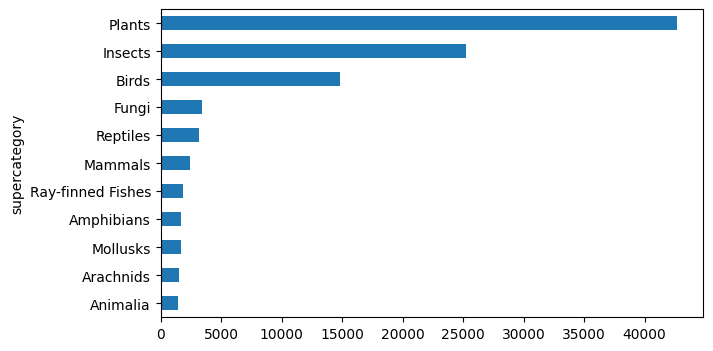

In [44]:
counts = df[LABEL_COLUMN].value_counts()
print(counts.to_frame("images"))
counts.sort_values().plot.barh(figsize=(7,4)).display

## 5. Draw the balanced sample
Plain random sampling within each class.

In [39]:
# needed to refrence: https://pandas.pydata.org/pandas-docs/version/1.5/reference/api/pandas.core.groupby.DataFrameGroupBy.sample.html
sample = df.groupby(LABEL_COLUMN,group_keys=False).sample(n=N_PER_CLASS,random_state=SEED).reset_index(drop=True)
print(sample[LABEL_COLUMN].value_counts())
print(sample.columns)

supercategory
Amphibians           200
Animalia             200
Arachnids            200
Birds                200
Fungi                200
Insects              200
Mammals              200
Mollusks             200
Plants               200
Ray-finned Fishes    200
Reptiles             200
Name: count, dtype: int64
Index(['image_id', 'width', 'height', 'file_name', 'license', 'rights_holder',
       'date', 'latitude', 'longitude', 'location_uncertainty',
       'annotation_id', 'category_id', 'species', 'common_name',
       'supercategory', 'kingdom', 'phylum', 'class', 'order', 'family',
       'genus', 'specific_epithet', 'image_dir_name'],
      dtype='object')


File list and meta_data_store

In [40]:
(LOCAL_DIR/"image_dir_names.txt").write_text("\n".join(sample.image_dir_name) + "\n")
sample.to_csv(LOCAL_DIR/"metadata.csv")

extract only the selected images

In [ ]:
if REDOWNLOAD_IMAGES:
    IMG_DIR=LOCAL_DIR/"images"
    file_list, count = set(sample.file_name), 0
    with open_stream(IMAGES_SOURCE) as stream:
        with tarfile.open(fileobj=stream, mode="r|gz") as tar:
            for member in tar:
                if member.name not in file_list:
                    continue
                dest= IMG_DIR/member.name
                dest.parent.mkdir(parents=True, exist_ok=True)
                dest.write_bytes(tar.extractfile(member).read())
                count += 1
print(str(count)+ " images counted")

2200 images counted


In [42]:
import shutil
zip_path = shutil.make_archive(str(LOCAL_DIR/"sample"), "zip", root_dir=LOCAL_DIR)